In [1]:
"""
PHASE 1: Dataset Load + EDA  (KAGGLE NOTEBOOK VERSION)
Paper: VersaModal (IJECE V12I6P121)
Dataset: Malaysia Restaurant Review Dataset

INSTRUCTIONS BEFORE RUNNING:
1. Create a New Notebook on Kaggle.
2. On the right panel, click "Add Input" -> search "Malaysia Restaurant Review Datasets"
   (by choonkhonng) -> Add.
3. Dataset will be mounted at /kaggle/input/malaysia-restaurant-review-datasets/
4. Paste this whole script in a cell and Run.
"""

import os
import pandas as pd

# ---------------------------------------------------------
# STEP 1: Locate dataset (already mounted by Kaggle, no download needed)
# ---------------------------------------------------------
DATA_DIR = "/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets"

print("Files found:")
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        print(os.path.join(root, f))

# ---------------------------------------------------------
# STEP 2: Load the dataset
# ---------------------------------------------------------
csv_files = []
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.endswith(".csv"):
            csv_files.append(os.path.join(root, f))

print("\nCSV files:", csv_files)

df = pd.read_csv(csv_files[0])
print("\nShape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nSample rows:")
print(df.head())
print("\nData types:\n", df.dtypes)

# ---------------------------------------------------------
# STEP 3: Basic EDA
# ---------------------------------------------------------
print("\nMissing values:\n", df.isnull().sum())

# IMPORTANT: After seeing the printed columns above, update these two names
# to match the actual review-text column and rating/label column.
TEXT_COL = "review_text"   # <-- change after checking df.columns output
LABEL_COL = "rating"       # <-- change after checking df.columns output

if TEXT_COL in df.columns:
    df["text_len"] = df[TEXT_COL].astype(str).apply(lambda x: len(x.split()))
    print("\nAverage word count per review:", df["text_len"].mean())
    print("Max word count:", df["text_len"].max())
else:
    print(f"\n[ACTION NEEDED] '{TEXT_COL}' not found. Set TEXT_COL to the correct "
          f"column name from: {df.columns.tolist()}")

if LABEL_COL in df.columns:
    print("\nUnique values in label column:", df[LABEL_COL].unique())
else:
    print(f"\n[ACTION NEEDED] '{LABEL_COL}' not found. Set LABEL_COL to the correct "
          f"column name from: {df.columns.tolist()}")

# ---------------------------------------------------------
# STEP 4: Sentiment label mapping (as per paper, Section 4.2)
# ---------------------------------------------------------
# Paper's score thresholds: Positive S>=0.5, Neutral -0.5<S<0.5, Negative S<=-0.5
# This dataset likely uses star ratings (1-5). Default mapping below:
#   Rating 4,5 -> Positive | Rating 3 -> Neutral | Rating 1,2 -> Negative
# UPDATE this once you confirm the actual rating scale from Step 3 output.

def map_rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

if LABEL_COL in df.columns:
    df["sentiment"] = df[LABEL_COL].apply(map_rating_to_sentiment)
    print("\nClass distribution:\n", df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 5: Save cleaned dataset for Phase 2 (Kaggle: save to /kaggle/working/)
# ---------------------------------------------------------
df.to_csv("/kaggle/working/cleaned_reviews.csv", index=False)
print("\nSaved to /kaggle/working/cleaned_reviews.csv for Phase 2 (preprocessing + split).")

Files found:
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data_cleaned/GoogleReview_data_cleaned.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data_cleaned/TripAdvisor_data_cleaned.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_JB.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_Shah Alam.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_Kuching.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/Malaysia Restaurant Review Datasets/data/review/TripAdvisor/reviews_all_Melaka.csv
/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/M

In [2]:
"""
PHASE 2: Label Mapping + Balanced Sampling + 80-20 Split (KAGGLE NOTEBOOK)
Paper: VersaModal (IJECE V12I6P121) - Section 4.1 & 4.2

Paper's text dataset setup:
  - 15k samples total: 5k positive, 5k negative, 5k neutral
  - 80% train / 20% test split
"""

import pandas as pd
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------
# STEP 1: Load the confirmed CSV (Google Review, cleaned)
# ---------------------------------------------------------
CSV_PATH = ("/kaggle/input/datasets/choonkhonng/malaysia-restaurant-review-datasets/"
            "Malaysia Restaurant Review Datasets/data_cleaned/GoogleReview_data_cleaned.csv")

df = pd.read_csv(CSV_PATH)
print("Original shape:", df.shape)

TEXT_COL = "Review"
LABEL_COL = "Rating"

# ---------------------------------------------------------
# STEP 2: Clean up
# ---------------------------------------------------------
df = df[[TEXT_COL, LABEL_COL]].dropna()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df = df[df[TEXT_COL].str.len() > 0]
df = df.drop_duplicates(subset=[TEXT_COL])
print("After cleaning:", df.shape)

# ---------------------------------------------------------
# STEP 3: Map Rating -> Sentiment (Positive / Neutral / Negative)
# ---------------------------------------------------------
def map_rating_to_sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["sentiment"] = df[LABEL_COL].apply(map_rating_to_sentiment)
print("\nFull class distribution:\n", df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 4: Balance dataset to match paper (5k per class = 15k total)
# ---------------------------------------------------------
N_PER_CLASS = 5000
SEED = 42

balanced_parts = []
for cls in ["Positive", "Neutral", "Negative"]:
    subset = df[df["sentiment"] == cls]
    available = len(subset)
    take = min(N_PER_CLASS, available)
    if available < N_PER_CLASS:
        print(f"[WARNING] Only {available} samples available for class '{cls}', "
              f"needed {N_PER_CLASS}. Taking all {available}.")
    balanced_parts.append(subset.sample(n=take, random_state=SEED))

balanced_df = pd.concat(balanced_parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
print("\nBalanced dataset shape:", balanced_df.shape)
print("Balanced class distribution:\n", balanced_df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 5: Encode labels
# ---------------------------------------------------------
label_map = {"Negative": 0, "Neutral": 1, "Positive": 2}
balanced_df["label"] = balanced_df["sentiment"].map(label_map)

# ---------------------------------------------------------
# STEP 6: 80-20 stratified split (paper protocol, Section 4.2)
# ---------------------------------------------------------
train_df, test_df = train_test_split(
    balanced_df,
    test_size=0.20,
    stratify=balanced_df["label"],
    random_state=SEED
)

print("\nTrain shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nTrain class distribution:\n", train_df["sentiment"].value_counts())
print("\nTest class distribution:\n", test_df["sentiment"].value_counts())

# ---------------------------------------------------------
# STEP 7: Save for Phase 3 (model training)
# ---------------------------------------------------------
train_df[[TEXT_COL, "sentiment", "label"]].to_csv("/kaggle/working/train.csv", index=False)
test_df[[TEXT_COL, "sentiment", "label"]].to_csv("/kaggle/working/test.csv", index=False)

print("\nSaved /kaggle/working/train.csv and /kaggle/working/test.csv for Phase 3.")

Original shape: (222020, 5)
After cleaning: (199171, 2)

Full class distribution:
 sentiment
Positive    156390
Neutral      22376
Negative     20405
Name: count, dtype: int64

Balanced dataset shape: (15000, 3)
Balanced class distribution:
 sentiment
Negative    5000
Neutral     5000
Positive    5000
Name: count, dtype: int64

Train shape: (12000, 4)
Test shape: (3000, 4)

Train class distribution:
 sentiment
Neutral     4000
Positive    4000
Negative    4000
Name: count, dtype: int64

Test class distribution:
 sentiment
Neutral     1000
Negative    1000
Positive    1000
Name: count, dtype: int64

Saved /kaggle/working/train.csv and /kaggle/working/test.csv for Phase 3.


UPDATED 

Using device: cuda


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

... (13 outputs left out)

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 - loss: 0.7306 - test_acc: 74.33%
Epoch 2/3 - loss: 0.5267 - test_acc: 73.83%
Epoch 3/3 - loss: 0.3836 - test_acc: 73.43%

Final -> Acc:73.43% Prec:73.80% Rec:73.43% F1:73.51% Time:3500.6s

CASE 3 RESULTS - BERT + RoBERTa Concatenation Fusion
                model      mode  accuracy  precision  recall    f1  train_time_sec
BERT+RoBERTa (Concat)    frozen     67.60      67.31   67.60 67.37          1828.0
BERT+RoBERTa (Concat) finetuned     73.43      73.80   73.43 73.51          3500.6


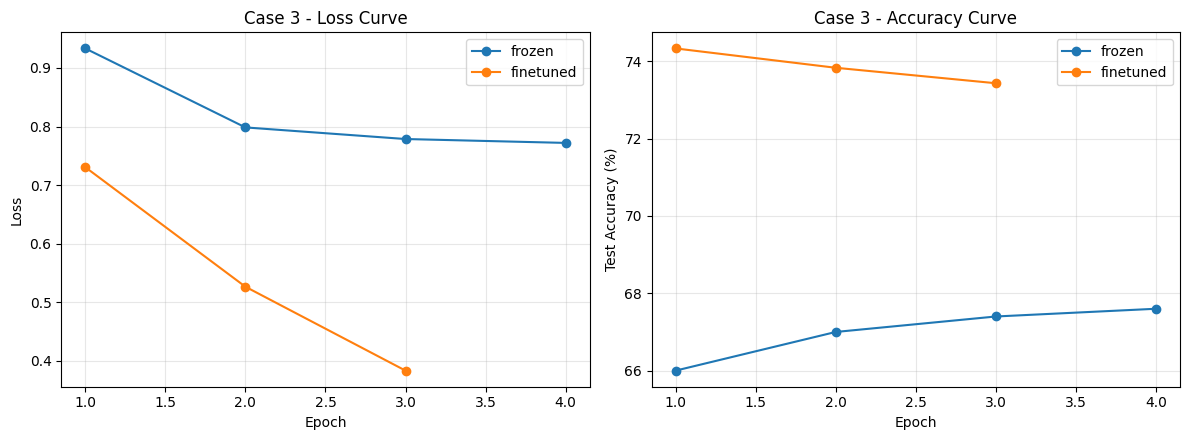

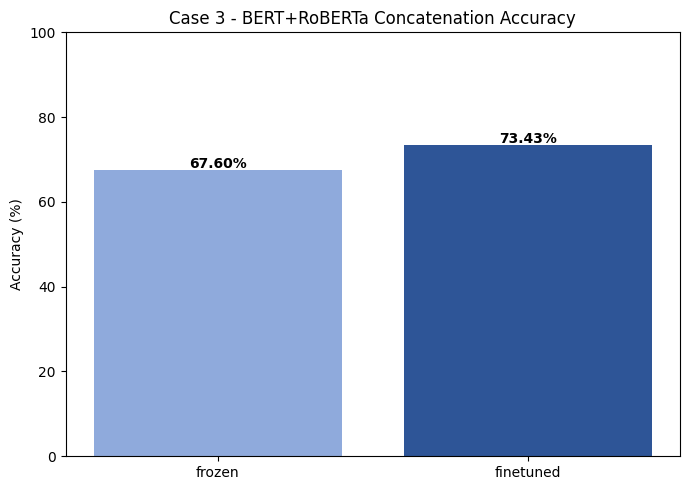

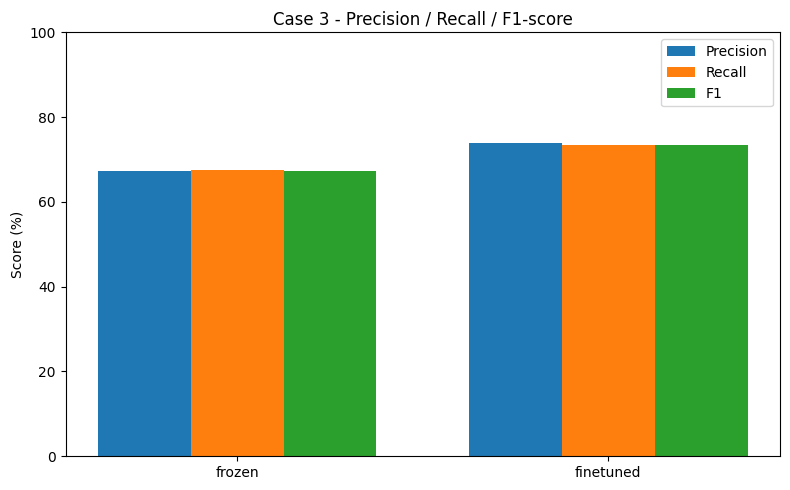

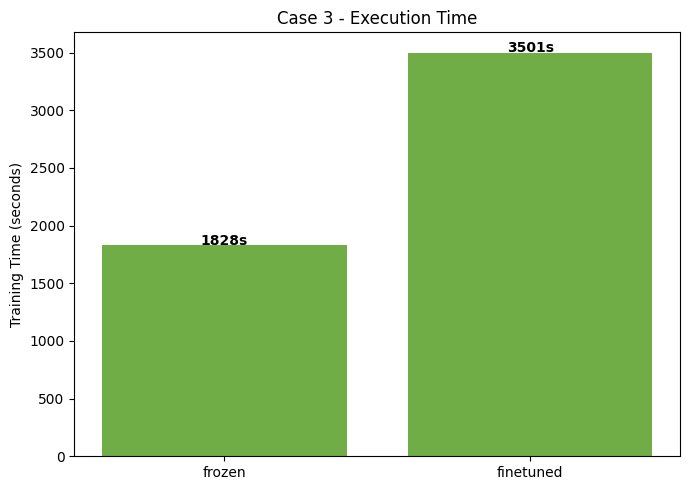

In [3]:
"""
CASE 3: BERT + RoBERTa CONCATENATION FUSION (all-in-one cell)
Architecture: Text -> [BERT encoder] -> CLS_bert (768-d)
              Text -> [RoBERTa encoder] -> CLS_roberta (768-d)
              Concatenate [CLS_bert ; CLS_roberta] -> 1536-d -> Classifier

Runs BOTH modes: frozen (backbones frozen, only classifier trains) and
fine-tuned (both backbones + classifier train end-to-end).
Prints results table + shows accuracy/loss graphs inline. No files saved.
"""

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ===================== CONFIG =====================
BERT_NAME = "bert-base-uncased"
ROBERTA_NAME = "roberta-base"
MAX_LEN = 256
BATCH_SIZE = 16   # lower than single-model runs since 2 backbones in memory together
NUM_CLASSES = 3
EPOCHS_FROZEN = 4
EPOCHS_FINETUNED = 3
LR_FROZEN = 5e-4
LR_FINETUNED = 2e-5
WARMUP_RATIO = 0.1
SEED = 42

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

train_df = pd.read_csv("/kaggle/working/train.csv")
test_df = pd.read_csv("/kaggle/working/test.csv")
TEXT_COL, LABEL_COL = "Review", "label"

bert_tok = AutoTokenizer.from_pretrained(BERT_NAME)
roberta_tok = AutoTokenizer.from_pretrained(ROBERTA_NAME)

# ===================== Dual-tokenizer Dataset =====================
class DualDataset(Dataset):
    def __init__(self, texts, labels, max_len):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        b = bert_tok(text, truncation=True, padding="max_length", max_length=self.max_len, return_tensors="pt")
        r = roberta_tok(text, truncation=True, padding="max_length", max_length=self.max_len, return_tensors="pt")
        return {
            "bert_ids": b["input_ids"].squeeze(0),
            "bert_mask": b["attention_mask"].squeeze(0),
            "roberta_ids": r["input_ids"].squeeze(0),
            "roberta_mask": r["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_loader = DataLoader(DualDataset(train_df[TEXT_COL], train_df[LABEL_COL], MAX_LEN),
                           batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(DualDataset(test_df[TEXT_COL], test_df[LABEL_COL], MAX_LEN),
                          batch_size=BATCH_SIZE, shuffle=False)

# ===================== Model =====================
class ConcatFusionModel(nn.Module):
    def __init__(self, num_classes, freeze=False):
        super().__init__()
        self.bert = AutoModel.from_pretrained(BERT_NAME)
        self.roberta = AutoModel.from_pretrained(ROBERTA_NAME)
        hidden = self.bert.config.hidden_size + self.roberta.config.hidden_size
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden, num_classes)
        if freeze:
            for p in self.bert.parameters(): p.requires_grad = False
            for p in self.roberta.parameters(): p.requires_grad = False

    def forward(self, bert_ids, bert_mask, roberta_ids, roberta_mask):
        b_out = self.bert(input_ids=bert_ids, attention_mask=bert_mask).last_hidden_state[:, 0, :]
        r_out = self.roberta(input_ids=roberta_ids, attention_mask=roberta_mask).last_hidden_state[:, 0, :]
        fused = torch.cat([b_out, r_out], dim=1)
        return self.classifier(self.dropout(fused))

# ===================== Train / Eval =====================
def train_epoch(model, loader, opt, crit, sched):
    model.train()
    total = 0
    for batch in loader:
        bi, bm = batch["bert_ids"].to(device), batch["bert_mask"].to(device)
        ri, rm = batch["roberta_ids"].to(device), batch["roberta_mask"].to(device)
        y = batch["label"].to(device)
        opt.zero_grad()
        logits = model(bi, bm, ri, rm)
        loss = crit(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if sched: sched.step()
        total += loss.item()
    return total / len(loader)

def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch in loader:
            bi, bm = batch["bert_ids"].to(device), batch["bert_mask"].to(device)
            ri, rm = batch["roberta_ids"].to(device), batch["roberta_mask"].to(device)
            y = batch["label"].to(device)
            logits = model(bi, bm, ri, rm)
            preds.extend(torch.argmax(logits, 1).cpu().numpy())
            labels.extend(y.cpu().numpy())
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return acc, p, r, f1

def run(mode):
    freeze = mode == "frozen"
    epochs = EPOCHS_FROZEN if freeze else EPOCHS_FINETUNED
    lr = LR_FROZEN if freeze else LR_FINETUNED
    print(f"\n{'='*60}\nCase 3: BERT+RoBERTa Concatenation | mode={mode} | epochs={epochs} | lr={lr}\n{'='*60}")

    model = ConcatFusionModel(NUM_CLASSES, freeze=freeze).to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    crit = nn.CrossEntropyLoss()
    total_steps = len(train_loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)

    history = {"epoch": [], "loss": [], "acc": []}
    start = time.time()
    for ep in range(epochs):
        loss = train_epoch(model, train_loader, opt, crit, sched)
        acc, _, _, _ = evaluate(model, test_loader)
        print(f"Epoch {ep+1}/{epochs} - loss: {loss:.4f} - test_acc: {acc*100:.2f}%")
        history["epoch"].append(ep+1); history["loss"].append(loss); history["acc"].append(acc*100)

    acc, p, r, f1 = evaluate(model, test_loader)
    duration = time.time() - start
    print(f"\nFinal -> Acc:{acc*100:.2f}% Prec:{p*100:.2f}% Rec:{r*100:.2f}% F1:{f1*100:.2f}% Time:{duration:.1f}s")

    return {"model": "BERT+RoBERTa (Concat)", "mode": mode, "accuracy": round(acc*100,2),
            "precision": round(p*100,2), "recall": round(r*100,2), "f1": round(f1*100,2),
            "train_time_sec": round(duration,1)}, history

# ===================== Run both modes =====================
results = []
histories = {}
for m in ["frozen", "finetuned"]:
    res, hist = run(m)
    results.append(res)
    histories[m] = hist

results_df = pd.DataFrame(results)
print("\n" + "="*80)
print("CASE 3 RESULTS - BERT + RoBERTa Concatenation Fusion")
print("="*80)
print(results_df.to_string(index=False))

# ===================== Graphs (inline only) =====================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["loss"], marker="o", label=m)
    axes[1].plot(hist["epoch"], hist["acc"], marker="o", label=m)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Case 3 - Loss Curve")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Test Accuracy (%)"); axes[1].set_title("Case 3 - Accuracy Curve")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["accuracy"], color=["#8FAADC","#2E5597"])
for bar, val in zip(bars, results_df["accuracy"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+0.5, f"{val:.2f}%", ha="center", fontweight="bold")
plt.ylabel("Accuracy (%)"); plt.title("Case 3 - BERT+RoBERTa Concatenation Accuracy")
plt.ylim(0,100)
plt.tight_layout()
plt.show()

# Precision / Recall / F1 grouped chart
metrics = ["precision", "recall", "f1"]
x = np.arange(len(results_df["mode"]))
width = 0.25
plt.figure(figsize=(8,5))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width, results_df[metric], width, label=metric.capitalize())
plt.xticks(x + width, results_df["mode"])
plt.ylabel("Score (%)"); plt.title("Case 3 - Precision / Recall / F1-score")
plt.ylim(0,100)
plt.legend()
plt.tight_layout()
plt.show()

# Execution time chart
plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["train_time_sec"], color="#70AD47")
for bar, val in zip(bars, results_df["train_time_sec"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+3, f"{val:.0f}s", ha="center", fontweight="bold")
plt.ylabel("Training Time (seconds)"); plt.title("Case 3 - Execution Time")
plt.tight_layout()
plt.show()

Using device: cuda

Case 4: BERT->RoBERTa Sequential | mode=frozen | epochs=4 | lr=0.0005


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/4 - loss: 1.0946 - test_acc: 47.43%
Epoch 2/4 - loss: 1.0656 - test_acc: 49.07%
Epoch 3/4 - loss: 1.0538 - test_acc: 51.27%
Epoch 4/4 - loss: 1.0500 - test_acc: 50.53%

Final -> Acc:50.53% Prec:50.08% Rec:50.53% F1:47.35% Time:1847.4s

Case 4: BERT->RoBERTa Sequential | mode=finetuned | epochs=3 | lr=2e-05


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 - loss: 0.8828 - test_acc: 70.87%
Epoch 2/3 - loss: 0.6577 - test_acc: 71.60%
Epoch 3/3 - loss: 0.5456 - test_acc: 72.87%

Final -> Acc:72.87% Prec:72.82% Rec:72.87% F1:72.76% Time:3478.5s

CASE 4 RESULTS - BERT -> RoBERTa Sequential
                     model      mode  accuracy  precision  recall    f1  train_time_sec
BERT->RoBERTa (Sequential)    frozen     50.53      50.08   50.53 47.35          1847.4
BERT->RoBERTa (Sequential) finetuned     72.87      72.82   72.87 72.76          3478.5


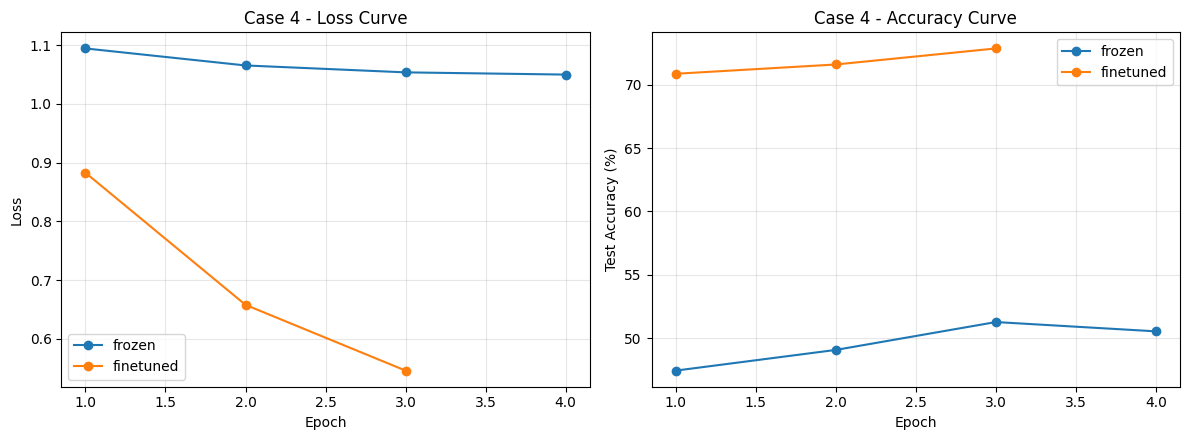

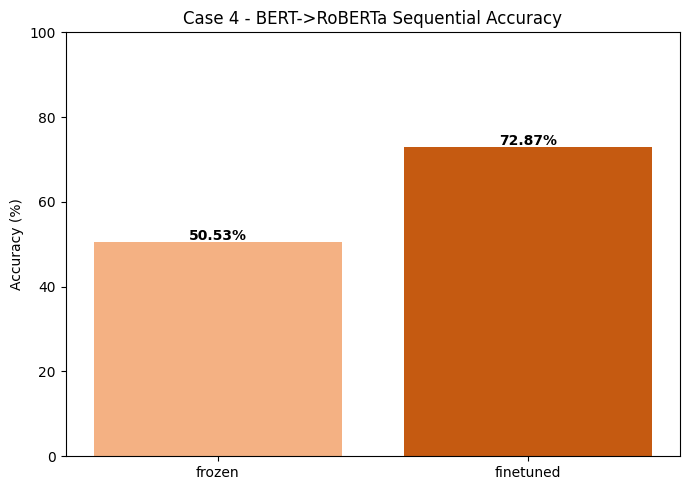

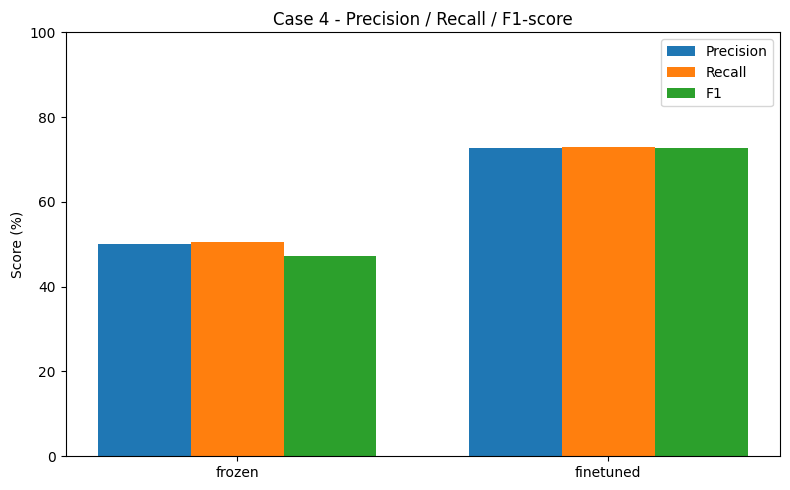

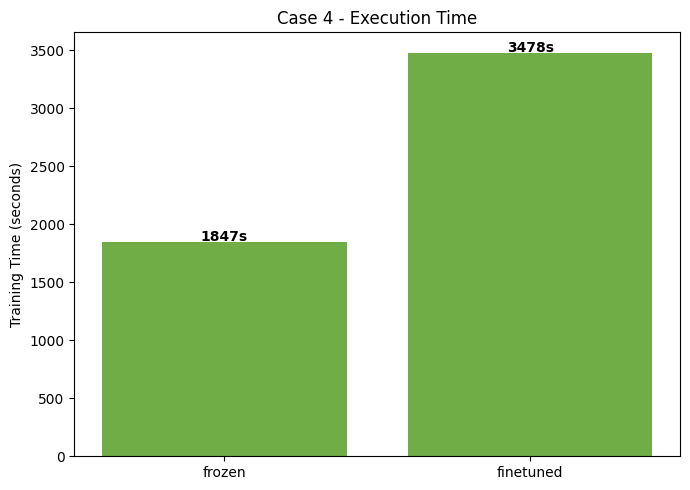

In [4]:
"""
CASE 4: BERT -> RoBERTa SEQUENTIAL (all-in-one cell)
Architecture: Text -> [BERT encoder] -> contextual hidden states (batch, seq_len, 768)
              -> fed as inputs_embeds INTO [RoBERTa encoder] (RoBERTa refines BERT's representations)
              -> RoBERTa's output at position 0 -> Classifier

Only ONE tokenizer needed (BERT's) since RoBERTa receives raw embeddings, not token ids.
Runs BOTH modes: frozen (backbones frozen) and fine-tuned (end-to-end).
Prints results table + shows accuracy/loss graphs inline. No files saved.
"""

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ===================== CONFIG =====================
BERT_NAME = "bert-base-uncased"
ROBERTA_NAME = "roberta-base"
MAX_LEN = 256
BATCH_SIZE = 16
NUM_CLASSES = 3
EPOCHS_FROZEN = 4
EPOCHS_FINETUNED = 3
LR_FROZEN = 5e-4
LR_FINETUNED = 2e-5
WARMUP_RATIO = 0.1
SEED = 42

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

train_df = pd.read_csv("/kaggle/working/train.csv")
test_df = pd.read_csv("/kaggle/working/test.csv")
TEXT_COL, LABEL_COL = "Review", "label"

bert_tok = AutoTokenizer.from_pretrained(BERT_NAME)

class SingleTokDataset(Dataset):
    def __init__(self, texts, labels, max_len):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = bert_tok(str(self.texts[idx]), truncation=True, padding="max_length",
                        max_length=self.max_len, return_tensors="pt")
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_loader = DataLoader(SingleTokDataset(train_df[TEXT_COL], train_df[LABEL_COL], MAX_LEN),
                           batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(SingleTokDataset(test_df[TEXT_COL], test_df[LABEL_COL], MAX_LEN),
                          batch_size=BATCH_SIZE, shuffle=False)

# ===================== Model =====================
class SequentialModel(nn.Module):
    def __init__(self, num_classes, freeze=False):
        super().__init__()
        self.bert = AutoModel.from_pretrained(BERT_NAME)
        self.roberta = AutoModel.from_pretrained(ROBERTA_NAME)
        hidden = self.roberta.config.hidden_size
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden, num_classes)
        if freeze:
            for p in self.bert.parameters(): p.requires_grad = False
            for p in self.roberta.parameters(): p.requires_grad = False

    def forward(self, input_ids, attention_mask):
        # Stage 1: BERT produces contextual token embeddings
        bert_hidden = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        # Stage 2: RoBERTa refines BERT's embeddings (skips RoBERTa's own word-embedding lookup)
        roberta_out = self.roberta(inputs_embeds=bert_hidden, attention_mask=attention_mask).last_hidden_state
        pooled = roberta_out[:, 0, :]
        return self.classifier(self.dropout(pooled))

# ===================== Train / Eval =====================
def train_epoch(model, loader, opt, crit, sched):
    model.train()
    total = 0
    for batch in loader:
        ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
        y = batch["label"].to(device)
        opt.zero_grad()
        logits = model(ids, mask)
        loss = crit(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if sched: sched.step()
        total += loss.item()
    return total / len(loader)

def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            y = batch["label"].to(device)
            logits = model(ids, mask)
            preds.extend(torch.argmax(logits, 1).cpu().numpy())
            labels.extend(y.cpu().numpy())
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return acc, p, r, f1

def run(mode):
    freeze = mode == "frozen"
    epochs = EPOCHS_FROZEN if freeze else EPOCHS_FINETUNED
    lr = LR_FROZEN if freeze else LR_FINETUNED
    print(f"\n{'='*60}\nCase 4: BERT->RoBERTa Sequential | mode={mode} | epochs={epochs} | lr={lr}\n{'='*60}")

    model = SequentialModel(NUM_CLASSES, freeze=freeze).to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    crit = nn.CrossEntropyLoss()
    total_steps = len(train_loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)

    history = {"epoch": [], "loss": [], "acc": []}
    start = time.time()
    for ep in range(epochs):
        loss = train_epoch(model, train_loader, opt, crit, sched)
        acc, _, _, _ = evaluate(model, test_loader)
        print(f"Epoch {ep+1}/{epochs} - loss: {loss:.4f} - test_acc: {acc*100:.2f}%")
        history["epoch"].append(ep+1); history["loss"].append(loss); history["acc"].append(acc*100)

    acc, p, r, f1 = evaluate(model, test_loader)
    duration = time.time() - start
    print(f"\nFinal -> Acc:{acc*100:.2f}% Prec:{p*100:.2f}% Rec:{r*100:.2f}% F1:{f1*100:.2f}% Time:{duration:.1f}s")

    return {"model": "BERT->RoBERTa (Sequential)", "mode": mode, "accuracy": round(acc*100,2),
            "precision": round(p*100,2), "recall": round(r*100,2), "f1": round(f1*100,2),
            "train_time_sec": round(duration,1)}, history

# ===================== Run both modes =====================
results = []
histories = {}
for m in ["frozen", "finetuned"]:
    res, hist = run(m)
    results.append(res)
    histories[m] = hist

results_df = pd.DataFrame(results)
print("\n" + "="*80)
print("CASE 4 RESULTS - BERT -> RoBERTa Sequential")
print("="*80)
print(results_df.to_string(index=False))

# ===================== Graphs (inline only) =====================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["loss"], marker="o", label=m)
    axes[1].plot(hist["epoch"], hist["acc"], marker="o", label=m)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Case 4 - Loss Curve")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Test Accuracy (%)"); axes[1].set_title("Case 4 - Accuracy Curve")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["accuracy"], color=["#F4B183","#C55A11"])
for bar, val in zip(bars, results_df["accuracy"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+0.5, f"{val:.2f}%", ha="center", fontweight="bold")
plt.ylabel("Accuracy (%)"); plt.title("Case 4 - BERT->RoBERTa Sequential Accuracy")
plt.ylim(0,100)
plt.tight_layout()
plt.show()

# Precision / Recall / F1 grouped chart
metrics = ["precision", "recall", "f1"]
x = np.arange(len(results_df["mode"]))
width = 0.25
plt.figure(figsize=(8,5))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width, results_df[metric], width, label=metric.capitalize())
plt.xticks(x + width, results_df["mode"])
plt.ylabel("Score (%)"); plt.title("Case 4 - Precision / Recall / F1-score")
plt.ylim(0,100)
plt.legend()
plt.tight_layout()
plt.show()

# Execution time chart
plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["train_time_sec"], color="#70AD47")
for bar, val in zip(bars, results_df["train_time_sec"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+3, f"{val:.0f}s", ha="center", fontweight="bold")
plt.ylabel("Training Time (seconds)"); plt.title("Case 4 - Execution Time")
plt.tight_layout()
plt.show()

Using device: cuda

Case 5: BERT<->RoBERTa Cross-Attention | mode=frozen | epochs=4 | lr=0.0005


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/4 - loss: 0.8059 - test_acc: 70.13%
Epoch 2/4 - loss: 0.6798 - test_acc: 71.67%
Epoch 3/4 - loss: 0.6433 - test_acc: 72.00%
Epoch 4/4 - loss: 0.6018 - test_acc: 73.07%

Final -> Acc:73.07% Prec:73.19% Rec:73.07% F1:73.01% Time:1868.8s

Case 5: BERT<->RoBERTa Cross-Attention | mode=finetuned | epochs=3 | lr=2e-05


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 - loss: 0.7795 - test_acc: 73.60%
Epoch 2/3 - loss: 0.5463 - test_acc: 74.10%
Epoch 3/3 - loss: 0.3997 - test_acc: 73.47%

Final -> Acc:73.47% Prec:73.72% Rec:73.47% F1:73.56% Time:3529.7s

CASE 5 RESULTS - BERT <-> RoBERTa Cross-Attention Fusion
                      model      mode  accuracy  precision  recall    f1  train_time_sec
BERT<->RoBERTa (Cross-Attn)    frozen     73.07      73.19   73.07 73.01          1868.8
BERT<->RoBERTa (Cross-Attn) finetuned     73.47      73.72   73.47 73.56          3529.7


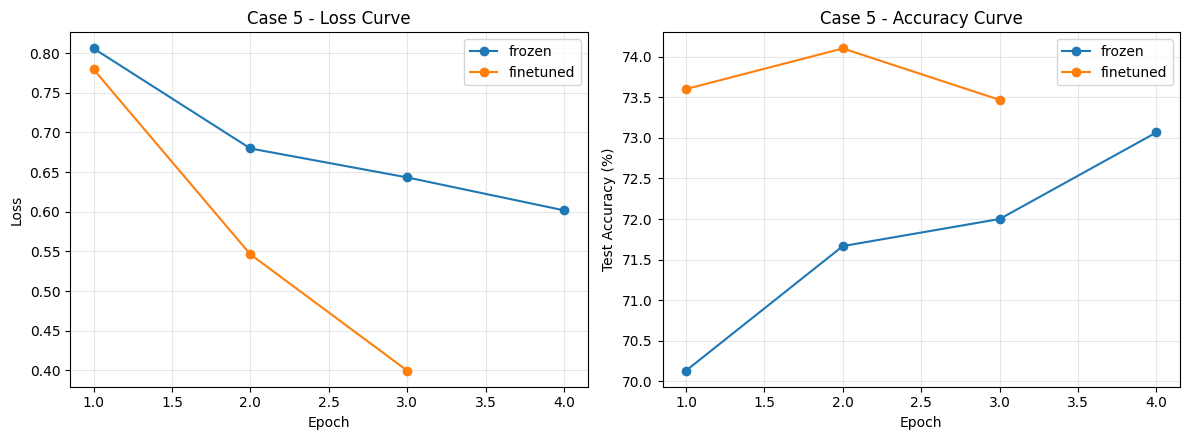

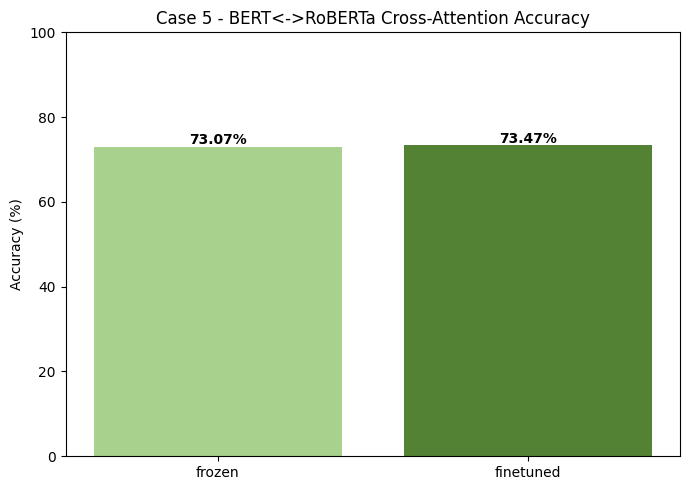

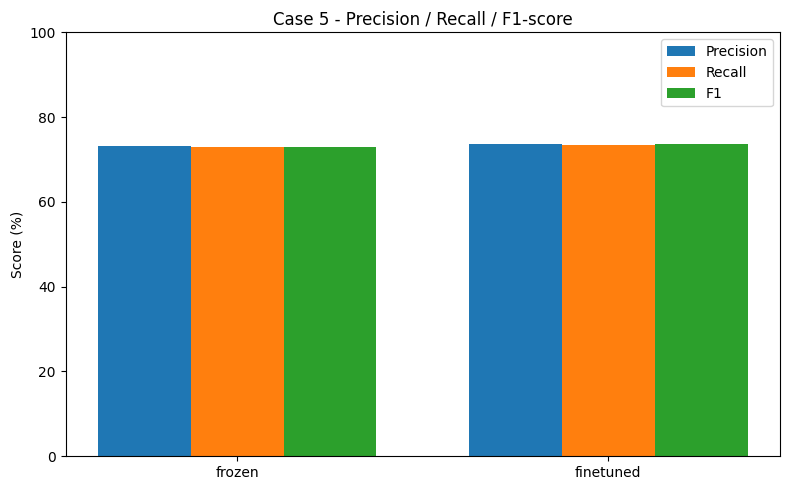

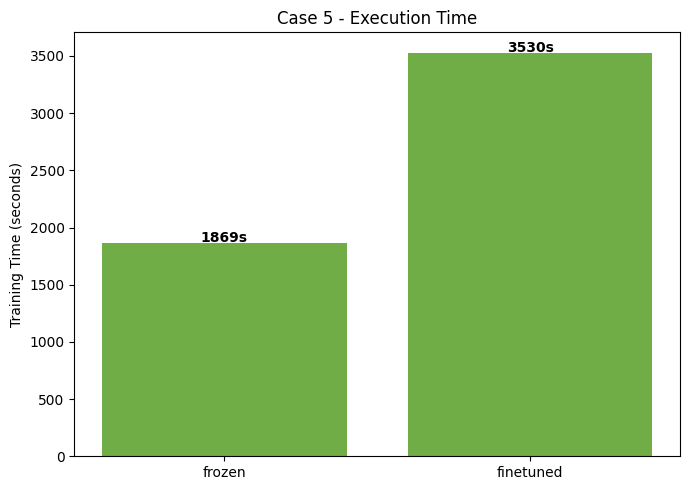

In [5]:
"""
CASE 5: BERT <-> RoBERTa CROSS-ATTENTION FUSION (all-in-one cell)
Architecture: Text -> [BERT encoder] -> full hidden states (batch, seq_len, 768)
              Text -> [RoBERTa encoder] -> CLS_roberta (batch, 768) as query
              Cross-Attention: RoBERTa's CLS attends over ALL of BERT's token hidden states
              -> fused context vector + residual with RoBERTa CLS -> Classifier

Runs BOTH modes: frozen (backbones frozen, only cross-attn + classifier train) and
fine-tuned (everything trains end-to-end).
Prints results table + shows accuracy/loss graphs inline. No files saved.
"""

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ===================== CONFIG =====================
BERT_NAME = "bert-base-uncased"
ROBERTA_NAME = "roberta-base"
MAX_LEN = 256
BATCH_SIZE = 16
NUM_CLASSES = 3
NUM_HEADS = 8
EPOCHS_FROZEN = 4
EPOCHS_FINETUNED = 3
LR_FROZEN = 5e-4
LR_FINETUNED = 2e-5
WARMUP_RATIO = 0.1
SEED = 42

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

train_df = pd.read_csv("/kaggle/working/train.csv")
test_df = pd.read_csv("/kaggle/working/test.csv")
TEXT_COL, LABEL_COL = "Review", "label"

bert_tok = AutoTokenizer.from_pretrained(BERT_NAME)
roberta_tok = AutoTokenizer.from_pretrained(ROBERTA_NAME)

class DualDataset(Dataset):
    def __init__(self, texts, labels, max_len):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        b = bert_tok(text, truncation=True, padding="max_length", max_length=self.max_len, return_tensors="pt")
        r = roberta_tok(text, truncation=True, padding="max_length", max_length=self.max_len, return_tensors="pt")
        return {
            "bert_ids": b["input_ids"].squeeze(0),
            "bert_mask": b["attention_mask"].squeeze(0),
            "roberta_ids": r["input_ids"].squeeze(0),
            "roberta_mask": r["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_loader = DataLoader(DualDataset(train_df[TEXT_COL], train_df[LABEL_COL], MAX_LEN),
                           batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(DualDataset(test_df[TEXT_COL], test_df[LABEL_COL], MAX_LEN),
                          batch_size=BATCH_SIZE, shuffle=False)

# ===================== Model =====================
class CrossAttentionFusionModel(nn.Module):
    def __init__(self, num_classes, freeze=False):
        super().__init__()
        self.bert = AutoModel.from_pretrained(BERT_NAME)
        self.roberta = AutoModel.from_pretrained(ROBERTA_NAME)
        hidden = self.bert.config.hidden_size  # 768, same for both
        self.cross_attn = nn.MultiheadAttention(embed_dim=hidden, num_heads=NUM_HEADS, batch_first=True)
        self.norm = nn.LayerNorm(hidden)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden, num_classes)
        if freeze:
            for p in self.bert.parameters(): p.requires_grad = False
            for p in self.roberta.parameters(): p.requires_grad = False

    def forward(self, bert_ids, bert_mask, roberta_ids, roberta_mask):
        bert_hidden = self.bert(input_ids=bert_ids, attention_mask=bert_mask).last_hidden_state  # (B, L, 768)
        roberta_out = self.roberta(input_ids=roberta_ids, attention_mask=roberta_mask).last_hidden_state
        roberta_cls = roberta_out[:, 0:1, :]  # (B, 1, 768) as query

        key_padding_mask = (bert_mask == 0)  # True where padded (to be ignored)
        attn_out, _ = self.cross_attn(query=roberta_cls, key=bert_hidden, value=bert_hidden,
                                       key_padding_mask=key_padding_mask)
        fused = self.norm(attn_out.squeeze(1) + roberta_out[:, 0, :])  # residual connection
        return self.classifier(self.dropout(fused))

# ===================== Train / Eval =====================
def train_epoch(model, loader, opt, crit, sched):
    model.train()
    total = 0
    for batch in loader:
        bi, bm = batch["bert_ids"].to(device), batch["bert_mask"].to(device)
        ri, rm = batch["roberta_ids"].to(device), batch["roberta_mask"].to(device)
        y = batch["label"].to(device)
        opt.zero_grad()
        logits = model(bi, bm, ri, rm)
        loss = crit(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if sched: sched.step()
        total += loss.item()
    return total / len(loader)

def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch in loader:
            bi, bm = batch["bert_ids"].to(device), batch["bert_mask"].to(device)
            ri, rm = batch["roberta_ids"].to(device), batch["roberta_mask"].to(device)
            y = batch["label"].to(device)
            logits = model(bi, bm, ri, rm)
            preds.extend(torch.argmax(logits, 1).cpu().numpy())
            labels.extend(y.cpu().numpy())
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    return acc, p, r, f1

def run(mode):
    freeze = mode == "frozen"
    epochs = EPOCHS_FROZEN if freeze else EPOCHS_FINETUNED
    lr = LR_FROZEN if freeze else LR_FINETUNED
    print(f"\n{'='*60}\nCase 5: BERT<->RoBERTa Cross-Attention | mode={mode} | epochs={epochs} | lr={lr}\n{'='*60}")

    model = CrossAttentionFusionModel(NUM_CLASSES, freeze=freeze).to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    crit = nn.CrossEntropyLoss()
    total_steps = len(train_loader) * epochs
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)

    history = {"epoch": [], "loss": [], "acc": []}
    start = time.time()
    for ep in range(epochs):
        loss = train_epoch(model, train_loader, opt, crit, sched)
        acc, _, _, _ = evaluate(model, test_loader)
        print(f"Epoch {ep+1}/{epochs} - loss: {loss:.4f} - test_acc: {acc*100:.2f}%")
        history["epoch"].append(ep+1); history["loss"].append(loss); history["acc"].append(acc*100)

    acc, p, r, f1 = evaluate(model, test_loader)
    duration = time.time() - start
    print(f"\nFinal -> Acc:{acc*100:.2f}% Prec:{p*100:.2f}% Rec:{r*100:.2f}% F1:{f1*100:.2f}% Time:{duration:.1f}s")

    return {"model": "BERT<->RoBERTa (Cross-Attn)", "mode": mode, "accuracy": round(acc*100,2),
            "precision": round(p*100,2), "recall": round(r*100,2), "f1": round(f1*100,2),
            "train_time_sec": round(duration,1)}, history

# ===================== Run both modes =====================
results = []
histories = {}
for m in ["frozen", "finetuned"]:
    res, hist = run(m)
    results.append(res)
    histories[m] = hist

results_df = pd.DataFrame(results)
print("\n" + "="*80)
print("CASE 5 RESULTS - BERT <-> RoBERTa Cross-Attention Fusion")
print("="*80)
print(results_df.to_string(index=False))

# ===================== Graphs (inline only) =====================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["loss"], marker="o", label=m)
    axes[1].plot(hist["epoch"], hist["acc"], marker="o", label=m)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Case 5 - Loss Curve")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Test Accuracy (%)"); axes[1].set_title("Case 5 - Accuracy Curve")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["accuracy"], color=["#A9D18E","#548235"])
for bar, val in zip(bars, results_df["accuracy"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+0.5, f"{val:.2f}%", ha="center", fontweight="bold")
plt.ylabel("Accuracy (%)"); plt.title("Case 5 - BERT<->RoBERTa Cross-Attention Accuracy")
plt.ylim(0,100)
plt.tight_layout()
plt.show()

# Precision / Recall / F1 grouped chart
metrics = ["precision", "recall", "f1"]
x = np.arange(len(results_df["mode"]))
width = 0.25
plt.figure(figsize=(8,5))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width, results_df[metric], width, label=metric.capitalize())
plt.xticks(x + width, results_df["mode"])
plt.ylabel("Score (%)"); plt.title("Case 5 - Precision / Recall / F1-score")
plt.ylim(0,100)
plt.legend()
plt.tight_layout()
plt.show()

# Execution time chart
plt.figure(figsize=(7,5))
bars = plt.bar(results_df["mode"], results_df["train_time_sec"], color="#70AD47")
for bar, val in zip(bars, results_df["train_time_sec"]):
    plt.text(bar.get_x()+bar.get_width()/2, val+3, f"{val:.0f}s", ha="center", fontweight="bold")
plt.ylabel("Training Time (seconds)"); plt.title("Case 5 - Execution Time")
plt.tight_layout()
plt.show()